## Part 1: Top products

Which products bring in the most revenue? 

In [14]:
import duckdb
con = duckdb.connect("../data/retail.duckdb", read_only=True)

In [5]:
con.sql("SELECT * FROM clean_sales LIMIT 10").show()

┌─────────┬────────────┬─────────────────────────────────────┬──────────┬─────────────────────┬────────┬─────────────┬────────────────┬─────────┐
│ invoice │ stock_code │             description             │ quantity │    invoice_date     │ price  │ customer_id │    country     │ revenue │
│ varchar │  varchar   │               varchar               │  int64   │      timestamp      │ double │   varchar   │    varchar     │ double  │
├─────────┼────────────┼─────────────────────────────────────┼──────────┼─────────────────────┼────────┼─────────────┼────────────────┼─────────┤
│ 501138  │ 85200      │ BUNNY EGG BOX                       │        5 │ 2010-03-14 12:05:00 │   1.25 │ 14532       │ United Kingdom │    6.25 │
│ 501142  │ 22584      │ PACK OF 6 PANNETONE GIFT BOXES      │        2 │ 2010-03-14 12:24:00 │   2.55 │ 17332       │ United Kingdom │     5.1 │
│ 501144  │ 22136      │ LOVE HEART SOCK HANGER              │        4 │ 2010-03-14 12:37:00 │   1.65 │ 14161       │ Unite

In [6]:
con.sql("""SELECT 
        description,
        ROUND(SUM(revenue), 2) AS total_revenue,
        SUM(quantity) AS total_quantity,
        COUNT(DISTINCT invoice) AS orders
    FROM clean_sales
    GROUP BY description
    ORDER BY total_revenue DESC
    LIMIT 10""").show()

┌─────────────────────────────────────┬───────────────┬────────────────┬────────┐
│             description             │ total_revenue │ total_quantity │ orders │
│               varchar               │    double     │     int128     │ int64  │
├─────────────────────────────────────┼───────────────┼────────────────┼────────┤
│ REGENCY CAKESTAND 3 TIER            │     330590.32 │          26478 │   3918 │
│ WHITE HANGING HEART T-LIGHT HOLDER  │     260990.22 │          94658 │   5455 │
│ PARTY BUNTING                       │     148318.28 │          28200 │   2674 │
│ JUMBO BAG RED RETROSPOT             │     148073.47 │          77699 │   3269 │
│ ASSORTED COLOUR BIRD ORNAMENT       │     129324.49 │          80082 │   2807 │
│ PAPER CHAIN KIT 50'S CHRISTMAS      │     117760.29 │          35084 │   2018 │
│ CHILLI LIGHTS                       │      80540.88 │          15841 │   1135 │
│ ROTATING SILVER ANGELS T-LIGHT HLDR │       71300.4 │          31409 │    756 │
│ JUMBO BAG STRA

In [7]:
con.sql("""SELECT stock_code,
        ANY_VALUE(description) AS description,
        ROUND(SUM(revenue), 2) AS total_revenue,
        SUM(quantity) AS total_quantity,
        COUNT(DISTINCT invoice) AS orders
    FROM clean_sales
    GROUP BY stock_code
    ORDER BY total_revenue DESC
    LIMIT 10""").show()

┌────────────┬─────────────────────────────────────┬───────────────┬────────────────┬────────┐
│ stock_code │             description             │ total_revenue │ total_quantity │ orders │
│  varchar   │               varchar               │    double     │     int128     │ int64  │
├────────────┼─────────────────────────────────────┼───────────────┼────────────────┼────────┤
│ 22423      │ REGENCY CAKESTAND 3 TIER            │     330590.32 │          26478 │   3918 │
│ 85123A     │ WHITE HANGING HEART T-LIGHT HOLDER  │     261168.73 │          94719 │   5464 │
│ 85099B     │ JUMBO BAG RED RETROSPOT             │     182680.98 │          97176 │   4013 │
│ 47566      │ PARTY BUNTING                       │     148318.28 │          28200 │   2674 │
│ 84879      │ ASSORTED COLOUR BIRD ORNAMENT       │     129324.49 │          80082 │   2807 │
│ 22086      │ PAPER CHAIN KIT 50'S CHRISTMAS      │     117760.29 │          35084 │   2018 │
│ 79321      │ CHILLI LIGHTS                      

In [8]:
con.sql("""SELECT COUNT(invoice) as invoice_cnt,
        stock_code,
        ANY_VALUE(description) AS description,
        ROUND(SUM(revenue),2) AS revenue
        FROM clean_sales
        WHERE description LIKE 'WHITE HANGING HEART%'
        GROUP BY stock_code
        ORDER BY invoice_cnt DESC
        """).show()

┌─────────────┬────────────┬────────────────────────────────────┬───────────┐
│ invoice_cnt │ stock_code │            description             │  revenue  │
│    int64    │  varchar   │              varchar               │  double   │
├─────────────┼────────────┼────────────────────────────────────┼───────────┤
│        5601 │ 85123A     │ WHITE HANGING HEART T-LIGHT HOLDER │ 260990.22 │
└─────────────┴────────────┴────────────────────────────────────┴───────────┘



In [13]:
con.sql("""SELECT *
        FROM clean_sales
        WHERE stock_code = '23843'
        AND ABS(quantity) > 10000
        """).show()

┌─────────┬────────────┬─────────────┬──────────┬──────────────┬────────┬─────────────┬─────────┬─────────┐
│ invoice │ stock_code │ description │ quantity │ invoice_date │ price  │ customer_id │ country │ revenue │
│ varchar │  varchar   │   varchar   │  int64   │  timestamp   │ double │   varchar   │ varchar │ double  │
└─────────┴────────────┴─────────────┴──────────┴──────────────┴────────┴─────────────┴─────────┴─────────┘
                                                  0 rows                                                 



In [11]:
con.sql("""SELECT *
        FROM clean_sales
        WHERE stock_code = '23166'
        AND ABS(quantity) > '10000'
        """).show()

┌─────────┬────────────┬─────────────┬──────────┬──────────────┬────────┬─────────────┬─────────┬─────────┐
│ invoice │ stock_code │ description │ quantity │ invoice_date │ price  │ customer_id │ country │ revenue │
│ varchar │  varchar   │   varchar   │  int64   │  timestamp   │ double │   varchar   │ varchar │ double  │
└─────────┴────────────┴─────────────┴──────────┴──────────────┴────────┴─────────────┴─────────┴─────────┘
                                                  0 rows                                                 



- **Dropped out:** 2 products were removed namely, Paper Craft, Little Birdie: £168,470 (invoice 581483) and Medium Ceramic Top Storage Jar: £81,701 (invoice 541431) because they were cancelled within minutes of being placed. Added cleaning rule in 02 to remove these specific invoices.

- **Came in:** Jumbo Bag Pink Polkadot and Rotating Silver Angels T-Light Holder replaced the 2 removed orders.

- **Went up:** The WHITE HANGING HEART T-LIGHT HOLDER (stock code 85123A) and JUMBO BAG RED RETROSPOT (stock code 85099B) gained a few more thousands in revenue because a new cleaning step was added to make stock codes in uppercase so that codes differing only in upper/lower case (e.g. 85123a and 85123A) are counted as one product.

## Part 2: Top countries

Which countries buy the most?

In [ ]:
con.sql("""SELECT country,
               ROUND(SUM(revenue), 2) AS revenue,
               ROUND(100.0 * SUM(revenue) / (SELECT SUM(revenue) FROM clean_sales), 2) AS pct_of_revenue,
               ROUND(SUM(revenue) / COUNT(DISTINCT invoice), 2) AS avg_order_value,
               COUNT(DISTINCT invoice) AS orders,
               COUNT(DISTINCT customer_id) AS customers
        FROM clean_sales
        GROUP BY country
        ORDER BY revenue DESC
        LIMIT 10""").show()

┌────────────────┬─────────────┬────────────────┬─────────────────┬────────┬───────────┐
│    country     │   revenue   │ pct_of_revenue │ avg_order_value │ orders │ customers │
│    varchar     │   double    │     double     │     double      │ int64  │   int64   │
├────────────────┼─────────────┼────────────────┼─────────────────┼────────┼───────────┤
│ United Kingdom │ 16555366.17 │          85.34 │          457.56 │  36182 │      5334 │
│ EIRE           │   623414.16 │           3.21 │          1073.0 │    581 │         3 │
│ Netherlands    │   549773.41 │           2.83 │         2545.25 │    216 │        22 │
│ Germany        │    383289.0 │           1.98 │          509.02 │    753 │       107 │
│ France         │   311090.29 │            1.6 │          520.22 │    598 │        93 │
│ Australia      │   167800.01 │           0.87 │         1885.39 │     89 │        15 │
│ Spain          │    97766.75 │            0.5 │          678.94 │    144 │        38 │
│ Switzerland    │   

- **Concentration:** Table shows that customers from the United Kingdom buy the most with £16,555,366.17 (85.34%) in total revenue. This shows that the business is well established in its home market, and the store depends mostly on its UK customers which is also a concentration risk: a downturn in the UK would hit most of the revenue.

- **Top international markets:** The next top countries based on revenue are EIRE (Ireland) with £623,414.16 (3.21%), Netherlands with £549,773.41 (2.83%), Germany with £383,289.0 (1.98%) and France with £311,090.29 (1.6%). Overall, they make up 9.62% (£1,867,566.86) of overall revenue. Moreover, it is shown that EIRE only has 3 customer accounts while Germany and France have more than 90 customer accounts. A broad customer base, like Germany's and France's, is a healthier base for growth than relying on a few large accounts.

- **Key-account risk:** Ireland (EIRE) is the second top country for revenue with 3.21% (£623,414.16) of total revenue. However, only 3 customer accounts were shown to be from Ireland so this presents a risk to the overall revenue. On average, each account is worth approximately £200k. Losing one would cost roughly a third of Ireland's revenue.

- **Order size:** Biggest order size based on the Average Order Value (AOV) came from customers from the Netherlands (£2,545.25), Australia (£1,885.39), and Denmark (£1,605.3). Comparing with £458 AOV for the UK, a Dutch order is about 5x larger. They are likely buying wholesale or in bulk to resell in their own shops.

In [ ]:
countries = con.sql("""SELECT country,
               ROUND(SUM(revenue), 2) AS revenue,
               ROUND(100.0 * SUM(revenue) / (SELECT SUM(revenue) FROM clean_sales), 2) AS pct_of_revenue,
               ROUND(SUM(revenue) / COUNT(DISTINCT invoice), 2) AS avg_order_value,
               COUNT(DISTINCT invoice) AS orders,
               COUNT(DISTINCT customer_id) AS customers
        FROM clean_sales
        WHERE country != 'United Kingdom'
        GROUP BY country
        ORDER BY revenue DESC
        LIMIT 10""").df()

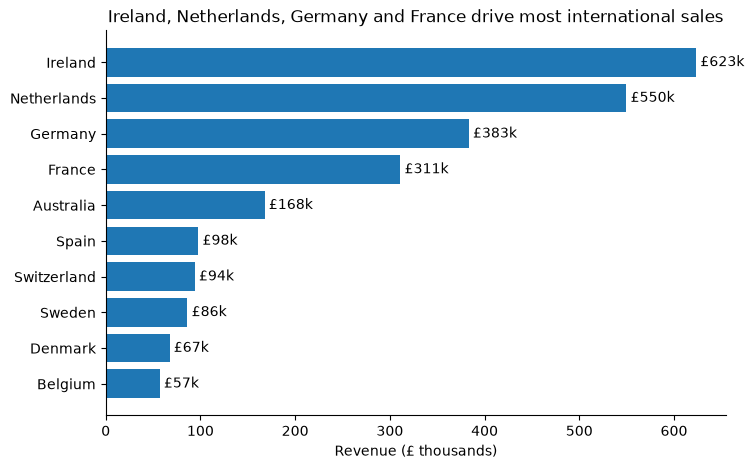

In [ ]:
import matplotlib.pyplot as plt

countries["country"] = countries["country"].replace("EIRE", "Ireland")

fig, ax = plt.subplots(figsize=(8, 5))
ax.invert_yaxis()                       # biggest at the top
ax.set_xlabel("Revenue (£ thousands)")
ax.set_title("Ireland, Netherlands, Germany and France drive most international sales")

bars = ax.barh(countries["country"], countries["revenue"] / 1000)   
ax.bar_label(bars, fmt="£%.0fk", padding=3)

ax.spines[["top", "right"]].set_visible(False)
fig.savefig("../images/top_international_markets.png", dpi=150, bbox_inches="tight")
plt.show()